# Goddard rocket · live demo

Pick a scenario from the paper's held-out grid, run every method once, and compare
altitude, velocity and throttle. Everything uses the shared RK4 evaluator in
`src/env.py` — including the learned agents.

Before running this notebook, generate the artefacts once:

```bash
python scripts/run_baselines.py --no-resume      # non-RL baselines
bash scripts/run_all_training.sh 120 3           # R0-R6 x 3 seeds
python src/evaluate.py --ablations all           # 18-scenario evaluation
```

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

ROOT = Path.cwd()
while not (ROOT / 'src' / 'env.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.baselines import build_baseline, evaluate_policy, make_env
from src.ppo import BetaActorCritic
from src.env import GoddardEnv
from src.evaluate import rollout_agent

CONFIG = yaml.safe_load((ROOT / 'configs' / 'scenarios.yaml').read_text())
SCENARIO = 'H_ST'          # <- change me: L_MT, L_Lo, N_ST, N_MT, H_T, H_MT, ...
EVAL_MODE = 'mean'         # 'mean' (CARL's table) or 'mode' (R6)
m_fuel_0 = CONFIG['scenarios'][SCENARIO]['m_fuel_0']
Q_max = CONFIG['scenarios'][SCENARIO]['Q_max']
print(SCENARIO, '| fuel', m_fuel_0, 'kg | Qmax', Q_max, 'Pa')
print('paper reference:', CONFIG['scenarios'][SCENARIO]['paper_apogee_m'])


H_ST | fuel 4000.0 kg | Qmax 10000.0 Pa
paper reference: {'bang_bang': 41337, 'mc_local_greedy': 49465, 'unconstrained_optimal': 46878, 'cc_only': 32905, 'cc_custom_skill': 42127, 'carl_init': 41216, 'carl_rev1': 42668, 'carl_final': 44687}


## Run every method

The analytic baselines are recomputed on the fly. The learned agent is the best
checkpoint available (R4 by default, falling back to any other ablation).

In [2]:
methods = ['bang_bang', 'unconstrained_optimal', 'mc_local_greedy']
rows, trajectories = [], {}
for method in methods:
    policy = build_baseline(method, {'m_fuel_0': m_fuel_0, 'Q_max': Q_max})
    env = make_env(m_fuel_0, Q_max, record_trajectory=True)
    result = evaluate_policy(env, policy, method=method, record_trajectory=True)
    rows.append({'method': method, 'apogee': round(result.apogee, 1),
                 'runtime_s': round(result.runtime_s, 2), 'clamps': result.n_clamp})
    trajectories[method] = result.trajectory

checkpoint = None
for ablation in ('R4', 'R6', 'R3', 'R5', 'R2', 'R1', 'R0'):
    found = sorted((ROOT / 'results' / 'checkpoints').glob(f'{ablation}_seed*.pt'))
    if found:
        checkpoint, (model, meta) = found[0], BetaActorCritic.load(found[0])
        break

if checkpoint is not None:
    env = GoddardEnv(
        params={'m_fuel_0': m_fuel_0, 'T_max': 200000.0, 'cd': 1.5, 'Q_max': Q_max},
        feature_mode=meta.get('feature_mode', 'base'),
        target_mode=meta.get('target_mode'),
        record_trajectory=True,
    )
    result = rollout_agent(model, env, eval_mode=EVAL_MODE, record_trajectory=True)
    rows.append({'method': checkpoint.stem, 'apogee': round(result['apogee'], 1),
                 'runtime_s': round(result['runtime_s'], 2), 'clamps': result['n_clamp']})
    trajectories[checkpoint.stem] = result['trajectory']
else:
    print('No trained checkpoint found - showing baselines only.')

paper = CONFIG['scenarios'][SCENARIO]['paper_apogee_m']
best_paper = max(paper.values())
table = pd.DataFrame(rows)
table['pct_of_paper_best'] = (100 * table['apogee'] / best_paper).round(1)
table

No trained checkpoint found - showing baselines only.


,method,apogee,runtime_s,clamps,pct_of_paper_best
0,bang_bang,41337.2,0.02,1056,83.6
1,unconstrained_optimal,44529.6,0.03,9,90.0
2,mc_local_greedy,49314.8,0.02,20,99.7


## Three-panel profile

The dashed line is `Qmax`; the throttle panel shows the *applied* thrust after the
max-Q clamp, so clamped steps are visible as plateaus below the commanded value.

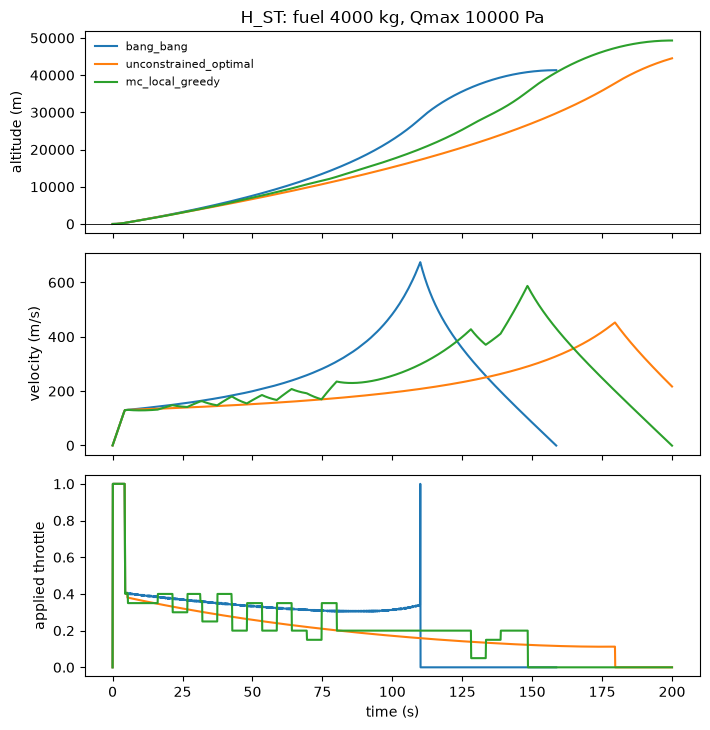

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(7.2, 7.4), sharex=True)
for method, data in trajectories.items():
    if not data:
        continue
    axes[0].plot(data['t'], data['h'], label=method)
    axes[1].plot(data['t'], data['v'])
    axes[2].plot(data['t'], data['u_applied'])
axes[0].axhline(0, color='black', lw=0.6)
axes[0].set_ylabel('altitude (m)')
axes[1].set_ylabel('velocity (m/s)')
axes[2].set_ylabel('applied throttle')
axes[2].set_xlabel('time (s)')
axes[0].set_title(f'{SCENARIO}: fuel {m_fuel_0:.0f} kg, Qmax {Q_max:.0f} Pa')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

## Ablation table

Produced by `python src/evaluate.py --ablations all`.

In [4]:
from IPython.display import Image, display

table_path = ROOT / 'results' / 'ablation_table.csv'
if table_path.exists():
    display(pd.read_csv(table_path).round(2))
else:
    print('Run src/evaluate.py first.')

for figure in ['ablation_bars.png', 'entropy_collapse.png', 'heatmap.png']:
    path = ROOT / 'results' / 'figures' / figure
    if path.exists():
        display(Image(filename=str(path)))


,method,kind,mean_apogee,std_over_seeds,mean_pct_best,worst_pct_best,light_pct_best,nominal_pct_best,heavy_pct_best
0,R4,RL,20862.6,NaN,95.94,70.82,99.73,99.46,88.63
1,R0,RL,16949.1,NaN,77.52,52.86,80.54,79.04,72.97
2,R1,RL,16813.1,NaN,77.30,50.61,80.79,78.93,72.18
3,casadi_optimum,baseline,22766.4,0.0,100.00,99.99,99.99,100.00,100.00
4,mc_local_greedy,baseline,22468.2,0.0,98.78,96.22,98.86,98.91,98.56
5,unconstrained_optimal,baseline,20026.2,0.0,93.84,44.77,99.99,98.66,82.88
6,bang_bang,baseline,16426.7,0.0,75.76,38.60,79.28,77.56,70.43


## Try it yourself

* Change `SCENARIO` to `H_MT` to see why the tightest dynamic-pressure limit is hardest.
* Set `EVAL_MODE = 'mode'` to compare the Beta mean against the Beta mode (the R6 fix).
* Call `build_baseline('casadi_optimum', ...)` for the direct-collocation upper bound
  (needs CasADi and a few seconds).